In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import pandas as pd

module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

In [4]:
from src.workflows.search_workflow import SearchWorkflow, SearchState
from src.utils.knowledge import Knowledge
from src.models.workflow import WorkflowSettings

In [8]:
from src.utils.injest import load_observation


df = load_observation('../../datasets/observations/Transactions.csv')
df.head()

,Id,Date,Amount,Entity,Entity_Id,Type,Category,Description,Mode,Related Party,Reference
0,1,5/26/2026,"₦680,000.00",Loan,NaN,Credit,Loan,Loan Investment,Transfer,Kennedy Ikeka,Credit_Loan_1
1,2,5/26/2026,"₦220,000.00",Pond,1,Debit,Utilities,Fish Pond Rent,Transfer,Kelechi,Debit_Utilities_1
2,3,5/29/2026,"₦19,000.00",Utility,1,Debit,Utilities,Fish Pond Net,Transfer,Rafiat Shonoiki,Debit_Utilities_2
3,4,5/31/2026,"₦11,000.00",Cycle,1,Debit,Inventory,Fish Stocking,Transfer,NaN,Debit_Inventory_1
4,5,6/1/2026,"₦13,036.00",Feed,1,Debit,Inventory,Fish Feed Stocking,Transfer,Lucky Eselojor,Debit_Inventory_2


In [9]:
km = Knowledge("testing")
km.ingest_from_dataframe(df, "testing")

[2026-11-21 15:47:08] [INFO] [Knowledge] - [Deleted document with id testing from vector store]
[2026-11-21 15:47:12] [INFO] [Knowledge] - [Ingested dataframe with id testing into vector store]


In [10]:
workflow = SearchWorkflow(['testing'], settings=WorkflowSettings(online=False))

In [11]:
workflow.invoke(SearchState(query="Category"))

[2026-11-21 15:47:24] [INFO] [SearchWorkflow] - [Invoked]
[2026-11-21 15:47:24] [INFO] [Knowledge] - [Looking for documents]


[2026-11-21 15:47:27] [INFO] [SearchWorkflow] - [Retrieved Documents]


[Document(id='testing_0', metadata={'file_id': 'testing'}, page_content='Id:1 | Date:5/26/2026 | Amount:₦680,000.00 | Entity:Loan | Entity_Id:nan | Type:Credit | Category:Loan | Description:Loan Investment | Mode:Transfer  | Related Party:Kennedy Ikeka | Reference:Credit_Loan_1\nId:2 | Date:5/26/2026 | Amount:₦220,000.00 | Entity:Pond | Entity_Id:1 | Type:Debit | Category:Utilities | Description:Fish Pond Rent | Mode:Transfer  | Related Party:Kelechi | Reference:Debit_Utilities_1\nId:3 | Date:5/29/2026 | Amount:₦19,000.00 | Entity:Utility | Entity_Id:1 | Type:Debit | Category:Utilities | Description:Fish Pond Net | Mode:Transfer  | Related Party:Rafiat Shonoiki | Reference:Debit_Utilities_2\nId:4 | Date:5/31/2026 | Amount:₦11,000.00 | Entity:Cycle | Entity_Id:1 | Type:Debit | Category:Inventory | Description:Fish Stocking | Mode:Transfer  | Related Party:nan | Reference:Debit_Inventory_1'),
 Document(id='testing_11', metadata={'file_id': 'testing'}, page_content='Id:45 | Date:11/11/202

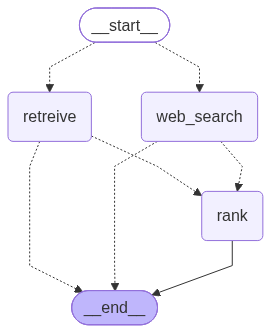

In [7]:
workflow.graph